
# 05 – Deep Learning Evaluation and Calibration

## Flight Club – Flight Delay Prediction

This notebook evaluates the trained Embedding MLP model using validation and test datasets.

The evaluation includes:
- Loading the best trained model checkpoint.
- Generating prediction probabilities.
- Classification metrics: Accuracy, Precision, Recall and F1-score.
- ROC-AUC and PR-AUC.
- Confusion matrix and classification report.
- Classification threshold selection using validation data.
- Brier score and probability calibration curves.
- Final evaluation on the untouched test dataset.

**Important:** The validation set is used for threshold selection and calibration decisions. The test set is reserved for final evaluation only.



In [26]:
import os
import sys
import json
import zipfile
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu



## 1. Load Project Files

We load the prepared dataset, model architecture and training checkpoint.

The training ZIP contains the best model checkpoint and training outputs. The dataset and model definition are uploaded separately.


In [27]:
# Check uploaded files
required_files = [
    "DL_Training_Results.zip",
    "dl_data (1).pt",
    "model.py",
    "model_config.json"
]

for file in required_files:
    print(file, "->", "Found" if os.path.exists(file) else "MISSING")

# Extract training results
os.makedirs("training_outputs", exist_ok=True)

with zipfile.ZipFile("DL_Training_Results.zip", "r") as zip_ref:
    zip_ref.extractall("training_outputs")

print("\nExtracted training ZIP.")

# Display extracted files
for root, dirs, files in os.walk("training_outputs"):
    for file in files:
        print(os.path.join(root, file))

DL_Training_Results.zip -> Found
dl_data (1).pt -> Found
model.py -> Found
model_config.json -> Found

Extracted training ZIP.
training_outputs/training_history.json
training_outputs/experiment_comparison.csv
training_outputs/best_training_loss.png
training_outputs/best_hyperparameters.json
training_outputs/best_model_checkpoint.pth


In [28]:
# Load dataset
data = torch.load(
    "dl_data (1).pt",
    map_location="cpu",
    weights_only=False
)

# Load model configuration
with open("model_config.json", "r") as f:
    model_config = json.load(f)

# Locate checkpoint
checkpoint_path = os.path.join(
    "training_outputs",
    "best_model_checkpoint.pth"
)

assert os.path.exists(checkpoint_path), (
    "Checkpoint not found. Check the extracted ZIP contents."
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Dataset loaded successfully.")
print("Model configuration loaded successfully.")
print("Best checkpoint loaded successfully.")

print("\nDataset keys:")
print(data.keys())

print("\nCheckpoint keys:")
print(checkpoint.keys())

Dataset loaded successfully.
Model configuration loaded successfully.
Best checkpoint loaded successfully.

Dataset keys:
dict_keys(['X_train_num', 'X_train_cat', 'y_train', 'X_val_num', 'X_val_cat', 'y_val', 'X_test_num', 'X_test_cat', 'y_test', 'numerical_features', 'categorical_features', 'category_maps', 'train_medians', 'scaler_mean', 'scaler_std'])

Checkpoint keys:
dict_keys(['model_state_dict', 'model_name', 'numerical_input_dim', 'category_sizes', 'embedding_dims', 'numerical_features', 'categorical_features', 'hidden_dims', 'dropout_rates', 'learning_rate', 'batch_size', 'class_weighting', 'positive_class_weight', 'best_validation_loss', 'best_epoch'])


In [29]:
# Expected dataset tensors
X_val_num = data["X_val_num"].float()
X_val_cat = data["X_val_cat"].long()
y_val = data["y_val"].float().view(-1)

X_test_num = data["X_test_num"].float()
X_test_cat = data["X_test_cat"].long()
y_test = data["y_test"].float().view(-1)

print("VALIDATION DATA")
print("Numerical features:", X_val_num.shape)
print("Categorical features:", X_val_cat.shape)
print("Labels:", y_val.shape)

print("\nTEST DATA")
print("Numerical features:", X_test_num.shape)
print("Categorical features:", X_test_cat.shape)
print("Labels:", y_test.shape)

print("\nValidation positive rate:", y_val.mean().item())
print("Test positive rate:", y_test.mean().item())

VALIDATION DATA
Numerical features: torch.Size([55628, 17])
Categorical features: torch.Size([55628, 4])
Labels: torch.Size([55628])

TEST DATA
Numerical features: torch.Size([53991, 17])
Categorical features: torch.Size([53991, 4])
Labels: torch.Size([53991])

Validation positive rate: 0.15051773190498352
Test positive rate: 0.24989350140094757



## 2. Reconstruct the Best Model

We reconstruct the Embedding MLP using the architecture stored in the best checkpoint.

The trained weights are then loaded into the model. The model is switched to evaluation mode so dropout is disabled during prediction.


In [30]:
# Import model architecture
from model import FlightDelayMLP

# Read architecture details from checkpoint
numerical_features = checkpoint["numerical_features"]
categorical_features = checkpoint["categorical_features"]

category_sizes = {
    feature: checkpoint["category_sizes"][feature]
    for feature in categorical_features
}

embedding_dims = {
    feature: checkpoint["embedding_dims"][feature]
    for feature in categorical_features
}

# Reconstruct model
model = FlightDelayMLP(
    numerical_input_dim=checkpoint["numerical_input_dim"],
    category_sizes=category_sizes,
    embedding_dims=embedding_dims,
    hidden_dims=tuple(checkpoint["hidden_dims"]),
    dropout_rates=tuple(checkpoint["dropout_rates"])
).to(device)

# Load trained weights
model.load_state_dict(checkpoint["model_state_dict"])

# Evaluation mode
model.eval()

print("Best trained model loaded successfully!")
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation loss:", checkpoint["best_validation_loss"])
print("Hidden dimensions:", checkpoint["hidden_dims"])
print("Dropout rates:", checkpoint["dropout_rates"])

Best trained model loaded successfully!
Best epoch: 5
Best validation loss: 0.41891881915901863
Hidden dimensions: [128, 64, 32]
Dropout rates: [0.3, 0.2]



## 3. Generate Validation Predictions

The model produces raw logits. We apply the sigmoid function to convert these logits into probabilities between 0 and 1.

A probability closer to 1 indicates a higher predicted likelihood of flight delay.


In [31]:
with torch.no_grad():
    val_logits = model(
        X_val_num.to(device),
        X_val_cat.to(device)
    )

    val_probabilities = (
        torch.sigmoid(val_logits)
        .cpu()
        .numpy()
        .reshape(-1)
    )

y_val_true = y_val.numpy().astype(int)

print("Validation predictions generated.")
print("Number of predictions:", len(val_probabilities))


print("\nFirst 10 probabilities:")
print(val_probabilities[:10])

Validation predictions generated.
Number of predictions: 55628

First 10 probabilities:
[0.18872957 0.15935338 0.20323528 0.16588487 0.13774991 0.13435274
 0.19407785 0.11441526 0.18029402 0.20444916]



## 4. Validation Classification Metrics

We initially use 0.50 as the classification threshold.

Predictions with probabilities greater than or equal to 0.50 are classified as delayed flights (class 1). Other predictions are classified as not delayed (class 0).


In [32]:
DEFAULT_THRESHOLD = 0.50

val_predictions_05 = (
    val_probabilities >= DEFAULT_THRESHOLD
).astype(int)

val_metrics = {
    "Accuracy": accuracy_score(y_val_true, val_predictions_05),
    "Precision": precision_score(
        y_val_true, val_predictions_05, zero_division=0
    ),
    "Recall": recall_score(
        y_val_true, val_predictions_05, zero_division=0
    ),
    "F1 Score": f1_score(
        y_val_true, val_predictions_05, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val_true, val_probabilities),
    "PR-AUC": average_precision_score(
        y_val_true, val_probabilities
    )
}

validation_metrics_df = pd.DataFrame(
    val_metrics.items(),
    columns=["Metric", "Value"]
)

display(validation_metrics_df)

,Metric,Value
0,Accuracy,0.846768
1,Precision,0.264798
2,Recall,0.010152
3,F1 Score,0.019554
4,ROC-AUC,0.624497
5,PR-AUC,0.211640


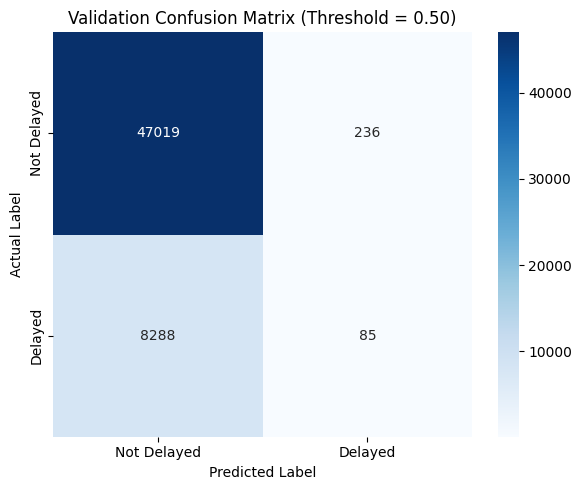

Validation Classification Report:

              precision    recall  f1-score   support

 Not Delayed       0.85      1.00      0.92     47255
     Delayed       0.26      0.01      0.02      8373

    accuracy                           0.85     55628
   macro avg       0.56      0.50      0.47     55628
weighted avg       0.76      0.85      0.78     55628



In [33]:
cm = confusion_matrix(y_val_true, val_predictions_05)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Delayed", "Delayed"],
    yticklabels=["Not Delayed", "Delayed"]
)

plt.title("Validation Confusion Matrix (Threshold = 0.50)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    "validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Validation Classification Report:\n")

print(
    classification_report(
        y_val_true,
        val_predictions_05,
        target_names=["Not Delayed", "Delayed"],
        zero_division=0
    )
)


## 5. ROC Curve

The ROC curve evaluates how well the model distinguishes between delayed and non-delayed flights across different classification thresholds.

The ROC-AUC score summarizes this discrimination ability.


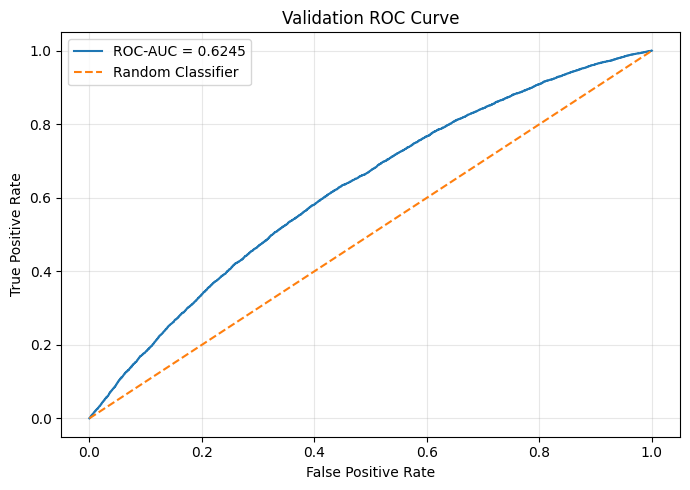

In [34]:
fpr, tpr, roc_thresholds = roc_curve(
    y_val_true,
    val_probabilities
)

val_roc_auc = roc_auc_score(
    y_val_true,
    val_probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {val_roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("validation_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

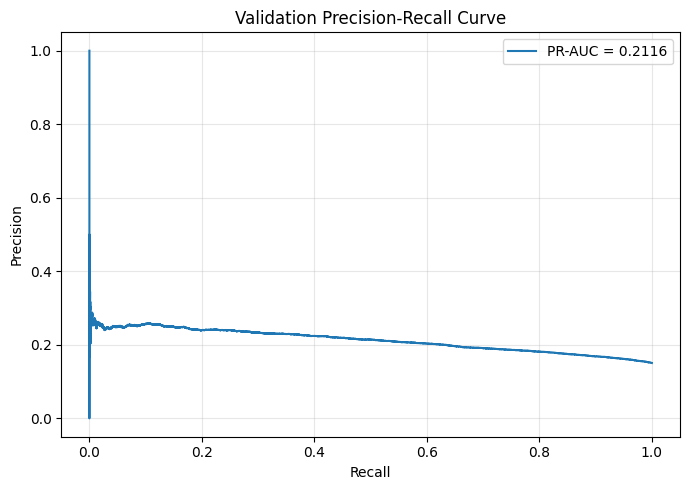

In [35]:
precision_vals, recall_vals, thresholds = precision_recall_curve(
    y_val_true,
    val_probabilities
)

val_pr_auc = average_precision_score(
    y_val_true,
    val_probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_vals,
    precision_vals,
    label=f"PR-AUC = {val_pr_auc:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("validation_pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Classification Threshold Selection

A threshold of 0.50 is not always optimal, especially when flight delays are imbalanced.

We use validation predictions to identify the threshold that maximizes the F1-score. This balances precision and recall.

The test dataset is not used for threshold selection.


In [36]:
# Calculate F1 for every available threshold
f1_values = (
    2 * precision_vals[:-1] * recall_vals[:-1]
    / (precision_vals[:-1] + recall_vals[:-1] + 1e-8)
)

best_f1_index = np.argmax(f1_values)

best_threshold = float(thresholds[best_f1_index])
best_val_f1 = float(f1_values[best_f1_index])

print("Best validation F1 threshold:", best_threshold)
print("Best validation F1 score:", best_val_f1)

# Predictions at selected threshold
val_predictions_best = (
    val_probabilities >= best_threshold
).astype(int)

print("\nMetrics at selected threshold:")
print(
    classification_report(
        y_val_true,
        val_predictions_best,
        target_names=["Not Delayed", "Delayed"],
        zero_division=0
    )
)

Best validation F1 threshold: 0.17645904421806335
Best validation F1 score: 0.30433353864397616

Metrics at selected threshold:
              precision    recall  f1-score   support

 Not Delayed       0.89      0.58      0.70     47255
     Delayed       0.20      0.61      0.30      8373

    accuracy                           0.58     55628
   macro avg       0.55      0.59      0.50     55628
weighted avg       0.79      0.58      0.64     55628




## 7. Operational Threshold Selection

In an operational setting, the airline may prefer a threshold that achieves a minimum precision while maximizing recall.

For this experiment, we use a target precision of 0.50 as an illustrative value. This should be replaced if the team has an agreed operational target.

Among thresholds meeting the target precision, we select the one with the highest recall.


In [37]:
TARGET_PRECISION = 0.50  # Illustrative target; confirm with the team.

eligible_indices = np.where(
    precision_vals[:-1] >= TARGET_PRECISION
)[0]

operational_threshold = None

if len(eligible_indices) > 0:

    operational_index = eligible_indices[
        np.argmax(recall_vals[:-1][eligible_indices])
    ]

    operational_threshold = float(
        thresholds[operational_index]
    )

    print("Operational threshold:", operational_threshold)
    print("Validation precision:", precision_vals[operational_index])
    print("Validation recall:", recall_vals[operational_index])

else:
    print(
        "No threshold achieved the target precision of",
        TARGET_PRECISION
    )

Operational threshold: 0.6146141290664673
Validation precision: 0.5
Validation recall: 0.00011943150603129105



## 8. Probability Calibration

Classification metrics evaluate predicted classes, but calibration evaluates whether predicted probabilities reflect actual event frequencies.

We use the Brier score and a calibration curve to assess probability quality.

A lower Brier score indicates better probabilistic predictions.


Validation Brier Score: 0.12788480601940916


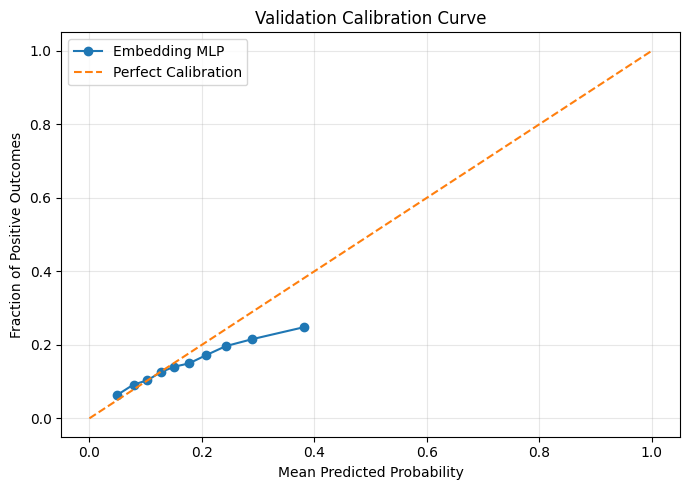

In [38]:
val_brier = brier_score_loss(
    y_val_true,
    val_probabilities
)

print("Validation Brier Score:", val_brier)

# Calibration curve
fraction_positive, mean_predicted = calibration_curve(
    y_val_true,
    val_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Embedding MLP"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positive Outcomes")
plt.title("Validation Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "validation_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [39]:
threshold_config = {
    "default_threshold": DEFAULT_THRESHOLD,
    "best_f1_threshold": best_threshold,
    "best_validation_f1": best_val_f1,
    "target_precision": TARGET_PRECISION,
    "operational_threshold": operational_threshold,
    "validation_brier_score": float(val_brier)
}

with open("threshold_config.json", "w") as f:
    json.dump(threshold_config, f, indent=4)

print("Threshold configuration saved.")

Threshold configuration saved.



## 9. Final Evaluation on the Test Dataset

The test dataset represents the final unseen period.

All model training, hyperparameter selection, threshold selection and calibration decisions have been made using training and validation data.

We now evaluate the model on the test dataset without changing the model or selected thresholds.


In [40]:
# Generate test predictions
with torch.no_grad():
    test_logits = model(
        X_test_num.to(device),
        X_test_cat.to(device)
    )

    test_probabilities = (
        torch.sigmoid(test_logits)
        .cpu()
        .numpy()
        .reshape(-1)
    )

y_test_true = y_test.numpy().astype(int)

print("Test predictions generated.")
print("Number of test predictions:", len(test_probabilities))

Test predictions generated.
Number of test predictions: 53991


In [41]:
def calculate_metrics(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_true, probabilities
        )
    }


# Default threshold
test_default_metrics = calculate_metrics(
    y_test_true,
    test_probabilities,
    DEFAULT_THRESHOLD
)

# Best F1 threshold selected on validation data
test_f1_metrics = calculate_metrics(
    y_test_true,
    test_probabilities,
    best_threshold
)

results = [
    {
        "Threshold Strategy": "Default 0.50",
        **test_default_metrics
    },
    {
        "Threshold Strategy": "Validation F1 Optimal",
        **test_f1_metrics
    }
]

# Operational threshold, if one was found
if operational_threshold is not None:

    test_operational_metrics = calculate_metrics(
        y_test_true,
        test_probabilities,
        operational_threshold
    )

    results.append({
        "Threshold Strategy": "Validation Operational",
        **test_operational_metrics
    })

test_metrics_df = pd.DataFrame(results)

display(test_metrics_df)

,Threshold Strategy,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Brier Score
0,Default 0.50,0.500000,0.750514,0.573333,0.006374,0.012608,0.637669,0.361152,0.181063
1,Validation F1 Optimal,0.176459,0.532830,0.309938,0.708939,0.431312,0.637669,0.361152,0.181063
2,Validation Operational,0.614614,0.750106,0.000000,0.000000,0.000000,0.637669,0.361152,0.181063


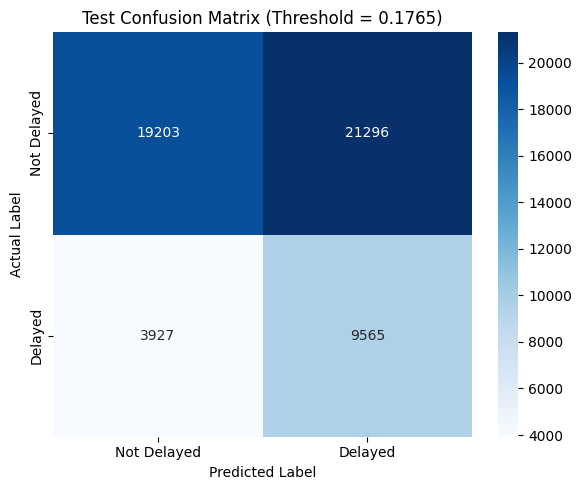

Final Test Classification Report:

              precision    recall  f1-score   support

 Not Delayed       0.83      0.47      0.60     40499
     Delayed       0.31      0.71      0.43     13492

    accuracy                           0.53     53991
   macro avg       0.57      0.59      0.52     53991
weighted avg       0.70      0.53      0.56     53991



In [42]:
# Use the validation-selected F1 threshold
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

test_cm = confusion_matrix(
    y_test_true,
    test_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Delayed", "Delayed"],
    yticklabels=["Not Delayed", "Delayed"]
)

plt.title(
    f"Test Confusion Matrix (Threshold = {best_threshold:.4f})"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final Test Classification Report:\n")

print(
    classification_report(
        y_test_true,
        test_predictions,
        target_names=["Not Delayed", "Delayed"],
        zero_division=0
    )
)

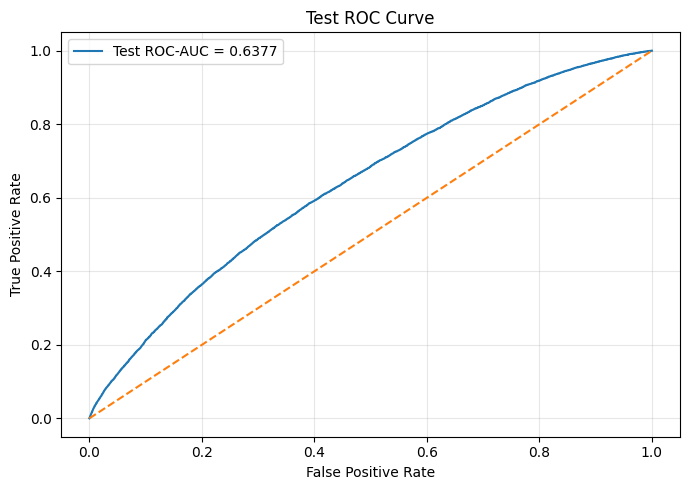

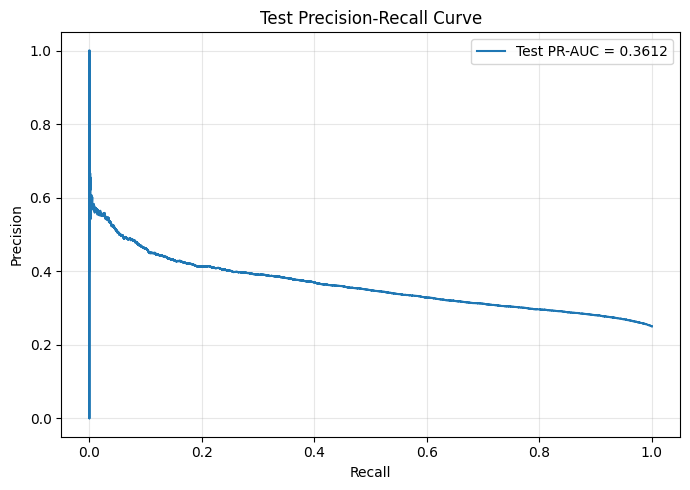

In [43]:
# ROC curve
test_fpr, test_tpr, _ = roc_curve(
    y_test_true,
    test_probabilities
)

test_roc_auc = roc_auc_score(
    y_test_true,
    test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    test_fpr,
    test_tpr,
    label=f"Test ROC-AUC = {test_roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("test_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()


# Precision-Recall curve
test_precision, test_recall, _ = precision_recall_curve(
    y_test_true,
    test_probabilities
)

test_pr_auc = average_precision_score(
    y_test_true,
    test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    test_recall,
    test_precision,
    label=f"Test PR-AUC = {test_pr_auc:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Test Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("test_pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

Final Test Brier Score: 0.181063114972149


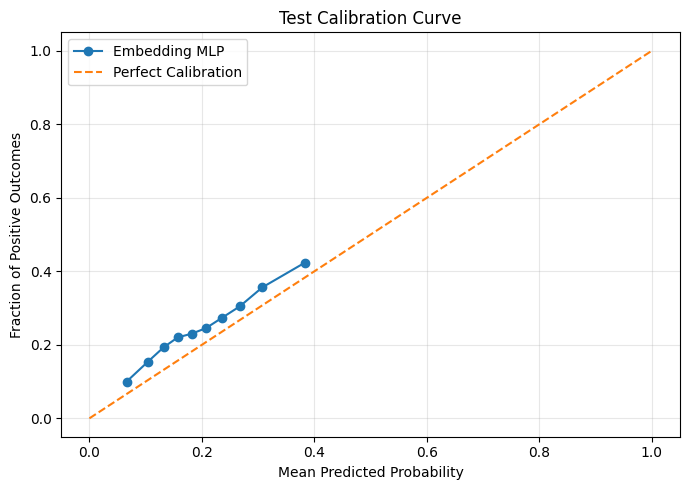

In [44]:
test_brier = brier_score_loss(
    y_test_true,
    test_probabilities
)

print("Final Test Brier Score:", test_brier)

test_fraction_positive, test_mean_predicted = calibration_curve(
    y_test_true,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    test_mean_predicted,
    test_fraction_positive,
    marker="o",
    label="Embedding MLP"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positive Outcomes")
plt.title("Test Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "test_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 10. Save Evaluation Results

We save the final evaluation metrics, selected thresholds, prediction probabilities and evaluation plots.

These outputs will be shared with Member 5 for the comparison between the traditional machine learning and deep learning models.


In [45]:
# Create output folder
output_dir = "dl_evaluation_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save test metrics
test_metrics_df.to_csv(
    os.path.join(output_dir, "test_metrics_comparison.csv"),
    index=False
)

# Save validation metrics
validation_metrics_df.to_csv(
    os.path.join(output_dir, "validation_metrics.csv"),
    index=False
)

# Save predictions
predictions_df = pd.DataFrame({
    "actual_label": y_test_true,
    "predicted_probability": test_probabilities,
    "predicted_label": test_predictions
})

predictions_df.to_csv(
    os.path.join(output_dir, "test_predictions.csv"),
    index=False
)

# Save threshold configuration
with open(
    os.path.join(output_dir, "threshold_config.json"),
    "w"
) as f:
    json.dump(threshold_config, f, indent=4)

# Save final evaluation summary
final_evaluation = {
    "model_name": "FlightDelayMLP",
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_validation_loss": float(
        checkpoint["best_validation_loss"]
    ),
    "validation_metrics_at_0.50": {
        key: float(value)
        for key, value in val_metrics.items()
    },
    "test_metrics_at_validation_f1_threshold": {
        key: float(value)
        for key, value in test_f1_metrics.items()
    },
    "test_brier_score": float(test_brier),
    "selected_f1_threshold": float(best_threshold),
    "operational_threshold": (
        float(operational_threshold)
        if operational_threshold is not None
        else None
    )
}

with open(
    os.path.join(output_dir, "final_evaluation.json"),
    "w"
) as f:
    json.dump(final_evaluation, f, indent=4)

# Copy saved plots into output folder
plot_files = [
    "validation_confusion_matrix.png",
    "validation_roc_curve.png",
    "validation_pr_curve.png",
    "validation_calibration_curve.png",
    "test_confusion_matrix.png",
    "test_roc_curve.png",
    "test_pr_curve.png",
    "test_calibration_curve.png"
]

for file in plot_files:
    if os.path.exists(file):
        shutil.copy(file, output_dir)

print("All evaluation outputs saved successfully!")

print("\nOutput files:")
for file in sorted(os.listdir(output_dir)):
    print("-", file)

All evaluation outputs saved successfully!

Output files:
- final_evaluation.json
- test_calibration_curve.png
- test_confusion_matrix.png
- test_metrics_comparison.csv
- test_pr_curve.png
- test_predictions.csv
- test_roc_curve.png
- threshold_config.json
- validation_calibration_curve.png
- validation_confusion_matrix.png
- validation_metrics.csv
- validation_pr_curve.png
- validation_roc_curve.png



## 11. Conclusion and Limitations

The Embedding MLP model was evaluated using chronological validation and test datasets.

The validation dataset was used for model evaluation, threshold selection and operational threshold analysis. The test dataset was reserved for final performance assessment.

The evaluation considered:
- Classification performance using accuracy, precision, recall and F1-score.
- Discrimination performance using ROC-AUC and PR-AUC.
- Probability quality using the Brier score and calibration curves.
- Classification behaviour using confusion matrices and classification reports.

### Limitations

1. Flight delay patterns may change over time, which can affect model generalization.
2. The model's performance depends on the quality and availability of input features.
3. The default classification threshold may not be optimal for operational use.
4. Predicted probabilities may require calibration before being interpreted as reliable delay probabilities.
5. The evaluation reflects the available dataset and may not represent all airline operations or future periods.

### Final Note

The test results represent the final evaluation of the trained deep learning model. No additional model tuning or threshold selection was performed using test labels.


In [46]:
from google.colab import files
import shutil
import os

# Create ZIP containing all evaluation outputs
zip_path = shutil.make_archive(
    "DL_Evaluation_Results",
    "zip",
    "dl_evaluation_outputs"
)

# Download ZIP to your computer
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>